# Multilingual Indic-to-English Neural Machine Translation (NMT)

## 1. Business problem

Organisations that serve India receive text in many Indian languages (customer tickets, reviews, news, forms), while analysts and downstream systems mostly work in English. The goal is **one system that reads a sentence written in an Indian language and returns an accurate English translation, together with a confidence signal** so that low-quality translations can be routed to a human reviewer.

**Machine-learning formulation.** Supervised, many-to-one multilingual sequence-to-sequence learning.
- Input: source sentence + its source language
- Output: English sentence
- Training signal: parallel pairs `(source_text, target_en)` from `train.parquet`

**Competition context (Kaggle hiring evaluation).** Build a production-grade multilingual NMT pipeline under these rules:
- the only allowed backbone is `facebook/m2m100_418M` (no NLLB, IndicTrans or other checkpoints, no translation APIs)
- training only on the provided `train.parquet`, inference fully local, single T4 GPU, 9-hour limit
- deliverables: `submission.csv`, a runnable self-contained notebook (this one) and a technical report

**Scope.** The data covers 7 languages: Hindi, Bengali, Tamil, Marathi, Gujarati, Malayalam, Urdu. The system does not claim coverage of every Indian language; adding one requires parallel data for it.

## Pipeline and validation gates

| Stage | Technique / tool | Validation gate |
|---|---|---|
| Data audit | pandas, duplicate / leakage checks | no train-test overlap, leak-free split |
| Preprocessing | Unicode NFC (Normalization Form C), invisible-character removal | token lengths and unknown-token rate checked |
| Split | `GroupShuffleSplit` grouped by English sentence | leak = 0.0 asserted |
| Baseline | zero-shot `m2m100_418M` | per-language reference scores |
| Fine-tuning | PyTorch + Hugging Face `Seq2SeqTrainer`, AdamW, label smoothing, fp16 | validation loss and BLEU / chrF++ |
| Decoding | beam search, `no_repeat_ngram_size` | ablation table on clean validation |
| Evaluation | `sacreBLEU` (BLEU, Bilingual Evaluation Understudy), chrF++ | per-language, macro average |
| Quality signal | sequence log-probability | correlation with real chrF++ |
| Delivery | `submission.csv`, demo function | format check against sample submission |

**How to run:** Colab (Runtime, then T4 GPU) or Kaggle (GPU T4, Internet on to download the model weights), then Run all. Colab asks for the competition zip if it is not found.

In [ ]:
# Install the libraries this notebook needs (safe to re-run)
%pip -q install transformers sentencepiece sacrebleu accelerate

In [ ]:
import os, glob, ctypes, site

# Preload the pip-installed CUDA 12 libs so ctranslate2 can find libcublas.so.12
for sp in site.getsitepackages():
    for lib in sorted(glob.glob(f"{sp}/nvidia/cublas/lib/libcublas*.so*") +
                      glob.glob(f"{sp}/nvidia/cudnn/lib/libcudnn*.so*")):
        try:
            ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL)
        except OSError:
            pass

import ctranslate2

In [ ]:
import os, glob, gc, re, random, unicodedata, zipfile, time
import numpy as np, pandas as pd, torch, sacrebleu

# ---------------- Run configuration ----------------
SEED = 42
RUN_BASELINE = True        # measure the zero-shot model first: the reference point for every later gain
TRAIN = True               # False = reload a saved model from MODEL_DIR instead of training again
EPOCHS, LR, WARMUP_STEPS = 4, 5e-5, 40
SRC_MAX, TGT_MAX = 160, 96 # token limits chosen from the token-length percentiles measured below
GEN_BASE  = dict(num_beams=4)                           # plain beam search
GEN_FINAL = dict(num_beams=5, no_repeat_ngram_size=3)   # blocks the repetition loops seen in zero-shot output

# Fix every random generator so the split and the results are reproducible
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")
WORK = "/kaggle/working" if ON_KAGGLE else "/content"
MODEL_DIR = f"{WORK}/final_model"

assert torch.cuda.is_available(), "No GPU found: switch the runtime to a T4 GPU and run again"
device = "cuda"
print("GPU:", torch.cuda.get_device_name(0), "| running on Kaggle:", ON_KAGGLE)

GPU: Tesla T4 | running on Kaggle: True


In [ ]:
import subprocess

# Show where the notebook runs and where the upload actually landed
print("cwd:", os.getcwd(), "| WORK:", WORK, "| ON_KAGGLE:", ON_KAGGLE)
found = subprocess.run("find / -name train.parquet -not -path '/proc/*' 2>/dev/null",
                       shell=True, capture_output=True, text=True).stdout.split()
print("train.parquet found at:", found)

assert found, "train.parquet is not on this runtime: upload the three files again"
DATA_DIR = os.path.dirname(found[0])
print("data folder:", DATA_DIR, os.listdir(DATA_DIR))

train = pd.read_parquet(f"{DATA_DIR}/train.parquet")
test  = pd.read_parquet(f"{DATA_DIR}/test_inputs.parquet")
sample_path = f"{DATA_DIR}/sample_submission.csv"
sample_sub = pd.read_csv(sample_path) if os.path.exists(sample_path) else None
print("train:", train.shape, "| test:", test.shape, "| columns:", train.columns.tolist())

cwd: /content | WORK: /kaggle/working | ON_KAGGLE: True
train.parquet found at: ['/content/train.parquet']
data folder: /content ['.config', 'train.parquet', 'sample_submission.csv', 'indic-multilingual-nmt.zip', 'test_inputs.parquet', 'sample_data']
train: (6800, 4) | test: (3563, 3) | columns: ['id', 'src_lang', 'source_text', 'target_en']


In [ ]:
import os

# The three uploaded files sit in the current working folder, so read them directly
print("cwd:", os.getcwd(), "| files:", [f for f in os.listdir(".") if f.endswith((".parquet", ".csv", ".zip"))])

train = pd.read_parquet("train.parquet")
test  = pd.read_parquet("test_inputs.parquet")
sample_sub = pd.read_csv("sample_submission.csv")    # later cells expect this exact name

print(train.shape, test.shape, sample_sub.shape)
print(train.columns.tolist(), test.columns.tolist(), sample_sub.columns.tolist())

cwd: /content | files: ['train.parquet', 'sample_submission.csv', 'indic-multilingual-nmt.zip', 'test_inputs.parquet']
(6800, 4) (3563, 3) (3563, 2)
['id', 'src_lang', 'source_text', 'target_en'] ['id', 'src_lang', 'source_text'] ['id', 'prediction']


## 2. Data loading and audit
The audit answers three questions before any modelling: how balanced are the languages, is the data clean, and is there any leakage between train and test.

In [ ]:
import os
import pandas as pd

DATA_DIR = "/content"

print(os.listdir(DATA_DIR))

train = pd.read_parquet(f"{DATA_DIR}/train.parquet")
test = pd.read_parquet(f"{DATA_DIR}/test_inputs.parquet")

sample_path = f"{DATA_DIR}/sample_submission.csv"
sample_sub = pd.read_csv(sample_path)

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample:", sample_sub.shape)

print("Columns:", train.columns.tolist())

['.config', 'train.parquet', 'sample_submission.csv', 'indic-multilingual-nmt.zip', 'test_inputs.parquet', 'sample_data']
Train: (6800, 4)
Test: (3563, 3)
Sample: (3563, 2)
Columns: ['id', 'src_lang', 'source_text', 'target_en']


In [ ]:
# Language balance: drives the evaluation choice (macro average) and the sampling discussion
print("train languages:", train.src_lang.value_counts().to_dict())
print("test languages: ", test.src_lang.value_counts().to_dict())

# Basic quality checks
print("nulls:", int(train.isnull().sum().sum()),
      "| duplicate pairs:", int(train.duplicated(["source_text", "target_en"]).sum()),
      "| train-test source overlap:", len(set(train.source_text) & set(test.source_text)))
print("source length (chars):", train.source_text.str.len().describe().round(1).to_dict())

# Multi-parallel check: the same English sentence may appear once per language.
# A random split would then leak answers from train into validation (handled by the grouped split below).
en_counts = train.target_en.value_counts()
print("unique English sentences:", len(en_counts),
      "| rows whose English sentence occurs in more than one row:",
      round(float((train.target_en.map(en_counts) > 1).mean()), 3))

train languages: {'hin': 1500, 'ben': 1300, 'tam': 1100, 'mar': 900, 'guj': 800, 'mal': 700, 'urd': 500}
test languages:  {'tam': 509, 'guj': 509, 'hin': 509, 'urd': 509, 'ben': 509, 'mal': 509, 'mar': 509}
nulls: 0 | duplicate pairs: 0 | train-test source overlap: 0
source length (chars): {'count': 6800.0, 'mean': 133.1, 'std': 47.5, 'min': 29.0, '25%': 99.0, '50%': 127.0, '75%': 160.0, 'max': 377.0}
unique English sentences: 1500 | rows whose English sentence occurs in more than one row: 0.971


## 3. Preprocessing, tokenizer checks and a leak-free split
Rule-based cleaning only (no extra pretrained models are allowed). The split is **grouped by English sentence** so that no sentence seen in training reappears in validation under another source language.

In [ ]:
from transformers import M2M100Tokenizer

# The dataset uses 3-letter codes, M2M100 uses 2-letter codes; all 7 languages are natively supported
MAP = {"hin": "hi", "ben": "bn", "tam": "ta", "mar": "mr", "guj": "gu", "mal": "ml", "urd": "ur"}
LANG_NAMES = {"hin": "Hindi", "ben": "Bengali", "tam": "Tamil", "mar": "Marathi",
              "guj": "Gujarati", "mal": "Malayalam", "urd": "Urdu"}
assert set(train.src_lang) <= set(MAP) and set(test.src_lang) <= set(MAP), "unexpected language code"

def norm(t):
    # NFC: Indic scripts can encode the same visible letter in several Unicode sequences,
    # and without normalization the tokenizer would treat them as different tokens
    t = unicodedata.normalize("NFC", str(t))
    t = re.sub(r"[\u200b\u200e\u200f\ufeff]", "", t)   # zero-width space, direction marks, BOM
    return re.sub(r"\s+", " ", t).strip()               # collapse repeated whitespace

for c in ["source_text", "target_en"]:
    train[c] = train[c].map(norm)
test["source_text"] = test["source_text"].map(norm)      # test rows are never dropped: every id needs a prediction

tok = M2M100Tokenizer.from_pretrained("facebook/m2m100_418M")
EN_ID = tok.get_lang_id("en")    # forces the decoder to start with the English language token

# Tokenizer diagnostics on a sample: sequence lengths justify SRC_MAX / TGT_MAX, unknown-token rate shows script coverage
probe = train.sample(500, random_state=SEED)
src_len = [len(tok(t).input_ids) for t in probe.source_text]
tgt_len = [len(tok(t).input_ids) for t in probe.target_en]
ids = np.array([i for t in probe.source_text for i in tok(t, add_special_tokens=False).input_ids])
print("source tokens p50/p95/p99/max:", np.percentile(src_len, [50, 95, 99, 100]))
print("target tokens p50/p95/p99/max:", np.percentile(tgt_len, [50, 95, 99, 100]))
print("unknown-token rate:", round(float((ids == tok.unk_token_id).mean()), 5))
if max(src_len) > SRC_MAX or max(tgt_len) > TGT_MAX:
    print("WARNING: some sampled sequences exceed the token limits and would be truncated")

tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/3.71M [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 2.42MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

source tokens p50/p95/p99/max: [ 48.    82.1  106.05 115.  ]
target tokens p50/p95/p99/max: [33.   52.05 61.01 83.  ]
unknown-token rate: 4e-05


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Group by the English sentence so every language version of a sentence lands on the same side of the split
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
tr_idx, val_idx = next(gss.split(train, groups=train.target_en))
tr  = train.iloc[tr_idx].reset_index(drop=True)
val = train.iloc[val_idx].reset_index(drop=True)

leak = float(val.target_en.isin(set(tr.target_en)).mean())
print("train:", len(tr), "| validation:", len(val), "| leak:", leak)
print("validation languages:", val.src_lang.value_counts().to_dict())
assert leak == 0.0, "validation still shares English sentences with train"

train: 6103 | validation: 697 | leak: 0.0
validation languages: {'hin': 150, 'ben': 129, 'tam': 116, 'mar': 94, 'guj': 83, 'mal': 72, 'urd': 53}


## 4. Translation and evaluation helpers
One function handles batching, language tokens and optional confidence scores, so the baseline, the fine-tuned model, the submission and the demo all use identical logic.

In [ ]:
@torch.no_grad()
def translate(model, texts, lang3, gen, bs=32, conf=False):
    # One call handles one source language, because the tokenizer prefixes the source language token
    tok.src_lang = MAP[lang3]
    order = np.argsort([len(t) for t in texts])           # length-sorted batches minimise padding
    hyp, score = [None] * len(texts), [np.nan] * len(texts)
    extra = dict(return_dict_in_generate=True, output_scores=True) if conf else {}
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tok([texts[j] for j in idx], return_tensors="pt", padding=True,
                  truncation=True, max_length=SRC_MAX).to(device)
        out = model.generate(**enc, forced_bos_token_id=EN_ID, max_length=TGT_MAX, **gen, **extra)
        seqs = out.sequences if conf else out
        dec = tok.batch_decode(seqs, skip_special_tokens=True)
        # With beam search, sequences_scores is the length-normalised log-probability of the chosen translation
        sc = out.sequences_scores.float().cpu().tolist() if conf else [np.nan] * len(idx)
        for k, j in enumerate(idx):
            hyp[j], score[j] = dec[k], sc[k]
    return hyp, score

def translate_df(model, df, gen, conf=False, bs=32):
    # Translate a dataframe language by language and return results aligned to the dataframe index
    hyp = pd.Series([None] * len(df), index=df.index, dtype=object)
    cs  = pd.Series(np.nan, index=df.index, dtype=float)
    for l, g in df.groupby("src_lang"):
        h, s = translate(model, g.source_text.tolist(), l, gen, bs=bs, conf=conf)
        hyp.loc[g.index], cs.loc[g.index] = h, s
    return hyp, cs

def evaluate(model, df, name, gen):
    # Per-language BLEU and chrF++ (chrF with word_order=2), then the macro average over languages
    hyp, _ = translate_df(model, df, gen)
    rows = []
    for l, g in df.groupby("src_lang"):
        h, ref = hyp.loc[g.index].tolist(), [g.target_en.tolist()]
        rows.append({"lang": l, "n": len(g),
                     "BLEU": sacrebleu.corpus_bleu(h, ref).score,
                     "chrF++": sacrebleu.corpus_chrf(h, ref, word_order=2).score})
    res = pd.DataFrame(rows).set_index("lang").round(2)
    print(f"\n{name}\n{res}\nMacro avg: {res[['BLEU', 'chrF++']].mean().round(2).to_dict()}")
    return res

## 5. Baseline: zero-shot `m2m100_418M`
Every later improvement is measured against this score on the same leak-free validation rows.

In [ ]:
from transformers import M2M100ForConditionalGeneration

results = {}
if RUN_BASELINE:
    base = M2M100ForConditionalGeneration.from_pretrained(
        "facebook/m2m100_418M", torch_dtype=torch.float16).to(device).eval()
    results["zero-shot, beam4"] = evaluate(base, val, "Zero-shot m2m100_418M", GEN_BASE)
    del base; gc.collect(); torch.cuda.empty_cache()    # free the GPU before training

config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.94GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.94GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]


Zero-shot m2m100_418M
        n   BLEU  chrF++
lang                    
ben   129  23.47   51.90
guj    83   1.63   13.37
hin   150  29.31   56.83
mal    72  16.87   43.63
mar    94  19.17   46.06
tam   116   6.58   29.64
urd    53  16.77   44.07
Macro avg: {'BLEU': 16.26, 'chrF++': 40.79}


## 6. Fine-tuning
Supervised fine-tuning with teacher forcing and cross-entropy loss with label smoothing (0.1), AdamW, linear warm-up and decay, fp16 mixed precision, gradient accumulation (effective batch 32) and gradient checkpointing to fit the T4. The decoder inputs are built explicitly in the data collator (labels shifted right), which keeps the code working across `transformers` versions.

In [ ]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

if TRAIN:
    tok.tgt_lang = "en"     # label sequences start with the English language token

    def encode(df):
        # The source language token depends on each row, so tokenize row by row
        rows = []
        for l, s, t in zip(df.src_lang, df.source_text, df.target_en):
            tok.src_lang = MAP[l]
            rows.append(tok(s, text_target=t, max_length=SRC_MAX, truncation=True))
        return rows

    train_ds, val_ds = encode(tr), encode(val)
    # Sanity check: the source starts with its language token and the labels start with __en__
    print(tok.convert_ids_to_tokens(train_ds[0]["input_ids"][:2]), tok.convert_ids_to_tokens(train_ds[0]["labels"][:2]))

    model = M2M100ForConditionalGeneration.from_pretrained("facebook/m2m100_418M").to(device)
    model.config.use_cache = False
    model.gradient_checkpointing_enable()     # trades speed for lower activation memory

    base_collator = DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100)   # -100 is ignored by the loss

    def collate(features):
        batch = base_collator(features)
        labels = batch["labels"]
        # Teacher forcing: decoder input = labels shifted right by one, starting with the decoder start token
        dec = labels.new_full(labels.shape, tok.pad_token_id)
        dec[:, 1:] = labels[:, :-1]
        dec[:, 0] = model.config.decoder_start_token_id
        dec[dec == -100] = tok.pad_token_id   # -100 is only valid inside labels
        batch["decoder_input_ids"] = dec
        return batch

    common = dict(
        output_dir=f"{WORK}/train_tmp",
        per_device_train_batch_size=8, gradient_accumulation_steps=4, per_device_eval_batch_size=16,
        learning_rate=LR, warmup_steps=WARMUP_STEPS, lr_scheduler_type="linear",
        num_train_epochs=EPOCHS, weight_decay=0.01, label_smoothing_factor=0.1,
        fp16=True, save_strategy="no", logging_steps=25, report_to="none", seed=SEED,
        remove_unused_columns=False,          # keep the decoder inputs created by the collator
    )
    try:
        args = Seq2SeqTrainingArguments(eval_strategy="epoch", **common)        # newer transformers
    except TypeError:
        args = Seq2SeqTrainingArguments(evaluation_strategy="epoch", **common)  # older transformers

    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds,
                             eval_dataset=val_ds, data_collator=collate)
    trainer.train()

    model = trainer.model.half().eval()       # fp16 for fast, memory-light inference
    model.config.use_cache = True
    model.save_pretrained(MODEL_DIR); tok.save_pretrained(MODEL_DIR)   # local disk: fast, reusable with TRAIN=False
    del trainer; gc.collect(); torch.cuda.empty_cache()
else:
    model = M2M100ForConditionalGeneration.from_pretrained(MODEL_DIR, torch_dtype=torch.float16).to(device).eval()
print("model ready")

['__gu__', '▁""'] ['__en__', '▁"']


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.908647,3.252496
2,2.349479,3.274501
3,2.074572,3.345634
4,1.904603,3.368372


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

model ready


## 7. Evaluation and ablation
All rows below use the same leak-free validation set. The ablation isolates what each step adds: fine-tuning first, then the decoding change.

In [ ]:
results["fine-tuned, beam4"] = evaluate(model, val, "Fine-tuned, beam 4", GEN_BASE)
results["fine-tuned, beam5 + no_repeat_ngram 3"] = evaluate(model, val, "Fine-tuned, beam 5 + no_repeat_ngram_size 3", GEN_FINAL)

summary = pd.DataFrame({k: v[["BLEU", "chrF++"]].mean() for k, v in results.items()}).T.round(2)
print("\n=== Ablation (macro average over languages) ===\n", summary)
print("\n=== BLEU per language ===\n", pd.DataFrame({k: v["BLEU"] for k, v in results.items()}))
print("\n=== chrF++ per language ===\n", pd.DataFrame({k: v["chrF++"] for k, v in results.items()}))


Fine-tuned, beam 4
        n   BLEU  chrF++
lang                    
ben   129  22.45   49.79
guj    83  14.70   39.66
hin   150  28.29   54.14
mal    72  16.74   42.64
mar    94  20.61   46.19
tam   116  12.14   36.58
urd    53  18.98   44.67
Macro avg: {'BLEU': 19.13, 'chrF++': 44.81}

Fine-tuned, beam 5 + no_repeat_ngram_size 3
        n   BLEU  chrF++
lang                    
ben   129  22.87   50.05
guj    83  16.45   40.81
hin   150  28.23   54.46
mal    72  17.60   43.84
mar    94  20.51   46.47
tam   116  13.61   38.16
urd    53  19.94   44.79
Macro avg: {'BLEU': 19.89, 'chrF++': 45.51}

=== Ablation (macro average over languages) ===
                                         BLEU  chrF++
zero-shot, beam4                       16.26   40.79
fine-tuned, beam4                      19.13   44.81
fine-tuned, beam5 + no_repeat_ngram 3  19.89   45.51

=== BLEU per language ===
       zero-shot, beam4  fine-tuned, beam4  \
lang                                        
ben              

In [ ]:
# Error analysis: inspect the weakest language under the final decoding setup
final = results["fine-tuned, beam5 + no_repeat_ngram 3"]
worst = final["chrF++"].idxmin()
g = val[val.src_lang == worst].head(300)
hyp, _ = translate_df(model, g, GEN_FINAL)
sent = pd.Series([sacrebleu.sentence_chrf(h, [r], word_order=2).score for h, r in zip(hyp, g.target_en)], index=g.index)
print("weakest language:", LANG_NAMES[worst], "| mean sentence chrF++:", round(float(sent.mean()), 2))
for i in sent.sort_values().index[:5]:
    print("\nSOURCE:", g.source_text[i][:110]); print("MODEL: ", hyp[i][:110]); print("REF:   ", g.target_en[i][:110])

weakest language: Tamil | mean sentence chrF++: 37.85

SOURCE: அவர், தான் வைஃபை கதவு அறிவிப்பு மணியை உருவாக்கியதாகக் கூறினார்.
MODEL:  He also stated that he was the first person to create a wifi service.
REF:    He built a WiFi door bell, he said.

SOURCE: அழகாய்த் தெரியும் முகமுடைய மா, வெறும் பாங்குதான், பொருள் இல்லை என்றும் ஹெசே கூறினார்.
MODEL:  Hsieh said the beauty of the face was worthwhile.
REF:    Hsieh also argued that the photogenic Ma was more style than substance.

SOURCE: """எங்களிடம் இப்போது 4-மாத-வயதுடைய எலி ஒன்று உள்ளது, முன்னர் அதற்கு நீரிழிவு இருந்தது தற்போது இல்லை"" என்று அவ
MODEL:  He added, "Today, we have a four-wheeled vehicle that wasn't yet damaged before.
REF:    "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.

SOURCE: நார்வேவில் குறிப்பிடத்தக்கது திடீரென்று உயர்ந்த, ஏறக்குறைய சமமான பீடபூமிக்கு வழிவகுக்கும் செங்குத்தான மலைப்பாற
MODEL:  The main things to do in Norway is the beach entrances and school routes between hil

## 8. Quality signal: does model confidence predict translation quality?
The business requirement includes knowing when a translation is unreliable. Using only the model's own sequence log-probability (no extra pretrained models), this section checks whether low confidence really corresponds to low quality, then sets a review threshold.

In [ ]:
# Confidence on a validation sample: sequence log-probability vs the true sentence-level chrF++
samp = val.sample(min(400, len(val)), random_state=SEED)
hyp, conf = translate_df(model, samp, GEN_FINAL, conf=True)
q = pd.Series([sacrebleu.sentence_chrf(h, [r], word_order=2).score for h, r in zip(hyp, samp.target_en)], index=samp.index)

# Spearman rank correlation = Pearson correlation of the ranks
spearman = conf.rank().corr(q.rank())
print("Spearman correlation (confidence vs chrF++):", round(float(spearman), 3))

# Quality by confidence quartile (0 = least confident, 3 = most confident)
bucket = pd.qcut(conf, 4, labels=False, duplicates="drop")
print(q.groupby(bucket).mean().round(2).rename("mean chrF++ per confidence quartile"))

# Translations below the 25th-percentile confidence are flagged for human review
CONF_THRESHOLD = float(conf.quantile(0.25))
print("review threshold (log-probability):", round(CONF_THRESHOLD, 3))

Spearman correlation (confidence vs chrF++): 0.683
0    33.25
1    41.23
2    48.95
3    58.17
Name: mean chrF++ per confidence quartile, dtype: float64
review threshold (log-probability): -0.655


## 9. Competition submission
Translate the full test set locally with the final decoding setup and validate the file format before saving.

In [ ]:
test = test.reset_index(drop=True)
t0 = time.time()
sub_hyp, _ = translate_df(model, test, GEN_FINAL)
sub = pd.DataFrame({"id": test["id"], "prediction": sub_hyp.values})

# Guard against empty outputs: fall back to the source text so no row is blank
empty = sub.prediction.isna() | (sub.prediction.astype(str).str.strip() == "")
print("empty predictions replaced:", int(empty.sum()))
sub.loc[empty, "prediction"] = test.loc[empty, "source_text"]

# Format checks against the sample submission
if sample_sub is not None:
    assert list(sub.columns) == list(sample_sub.columns), "column names differ from the sample submission"
    assert set(sub["id"].astype(str)) == set(sample_sub["id"].astype(str)), "ids differ from the sample submission"
assert len(sub) == len(test) and sub.prediction.notna().all()

out_path = f"{WORK}/submission.csv"
sub.to_csv(out_path, index=False)
print(f"saved {out_path} | rows: {len(sub)} | time: {round((time.time() - t0) / 60, 1)} min")
print(sub.head())

if not ON_KAGGLE:
    try:
        from google.colab import files
        files.download(out_path)      # browser download for the Kaggle upload
    except Exception as e:
        print("download skipped:", e)

empty predictions replaced: 0
saved /kaggle/working/submission.csv | rows: 3563 | time: 3.8 min
     id                                         prediction
0  6800  At the top end of all, the team's success and ...
1  6801  The correct use of blogs can make students mor...
2  6802  Maldives are a multi-ethnical republic that is...
3  6803  The population's balance makes many people won...
4  6804  According to park authorities, stay at least 1...


## 10. Demo: translate any supported Indian-language sentence into English
`translate_text` normalises the text, detects the language from its Unicode script (rule-based), translates, and returns the English text with a confidence flag. Hindi and Marathi share the Devanagari script, so Marathi must be passed explicitly with `lang="mar"`; unsupported scripts are rejected instead of translated badly.

In [ ]:
# Unicode block for each supported script (Hindi and Marathi share Devanagari; Urdu uses the Arabic script)
SCRIPT_RANGES = {"hin": (0x0900, 0x097F), "ben": (0x0980, 0x09FF), "guj": (0x0A80, 0x0AFF),
                 "tam": (0x0B80, 0x0BFF), "mal": (0x0D00, 0x0D7F), "urd": (0x0600, 0x06FF)}

def detect_lang(text):
    # Count characters per script and return the dominant one; None if no supported script is present
    counts = {l: sum(a <= ord(ch) <= b for ch in text) for l, (a, b) in SCRIPT_RANGES.items()}
    best = max(counts, key=counts.get)
    return best if counts[best] > 0 else None

def translate_text(text, lang=None, gen=GEN_FINAL):
    text = norm(text)
    lang = lang or detect_lang(text)
    if lang not in MAP:
        return {"error": "Unsupported or undetected script. Supported: " + ", ".join(LANG_NAMES.values())}
    hyp, sc = translate(model, [text], lang, gen, conf=True)
    return {"language": LANG_NAMES[lang], "english": hyp[0], "confidence": round(float(sc[0]), 3),
            "flag": "OK" if sc[0] >= CONF_THRESHOLD else "REVIEW"}

demo = [("नमस्ते, आप कैसे हैं?", None),
        ("তুমি কেমন আছো?", None),
        ("நீங்கள் எப்படி இருக்கிறீர்கள்?", None),
        ("તમે કેમ છો?", None),
        ("നിങ്ങൾക്ക് സുഖമാണോ?", None),
        ("آپ کیسے ہیں؟", None),
        ("तुम्ही कसे आहात?", "mar")]      # Marathi must be given explicitly
for text, lang in demo:
    print(text, "->", translate_text(text, lang))

print(translate_text("मेरा नाम कैप्टन अमेरिका है।"))

नमस्ते, आप कैसे हैं? -> {'language': 'Hindi', 'english': 'Hello, how do you feel?', 'confidence': -0.489, 'flag': 'OK'}
তুমি কেমন আছো? -> {'language': 'Bengali', 'english': 'How do you feel?', 'confidence': -0.403, 'flag': 'OK'}
நீங்கள் எப்படி இருக்கிறீர்கள்? -> {'language': 'Tamil', 'english': 'How are you going to feel?', 'confidence': -0.309, 'flag': 'OK'}
તમે કેમ છો? -> {'language': 'Gujarati', 'english': 'How do you feel?', 'confidence': -0.411, 'flag': 'OK'}
നിങ്ങൾക്ക് സുഖമാണോ? -> {'language': 'Malayalam', 'english': 'Do you feel well?', 'confidence': -0.301, 'flag': 'OK'}
آپ کیسے ہیں؟ -> {'language': 'Urdu', 'english': 'How are you?', 'confidence': -0.217, 'flag': 'OK'}
तुम्ही कसे आहात? -> {'language': 'Marathi', 'english': 'How are you doing?', 'confidence': -0.446, 'flag': 'OK'}
{'error': 'Unsupported or undetected script. Supported: Hindi, Bengali, Tamil, Marathi, Gujarati, Malayalam, Urdu'}


In [ ]:
# Try your own sentence:
print(translate_text("मुझे लघुशंका जाना है"))

{'language': 'Hindi', 'english': 'I have to go shy.', 'confidence': -0.545, 'flag': 'OK'}


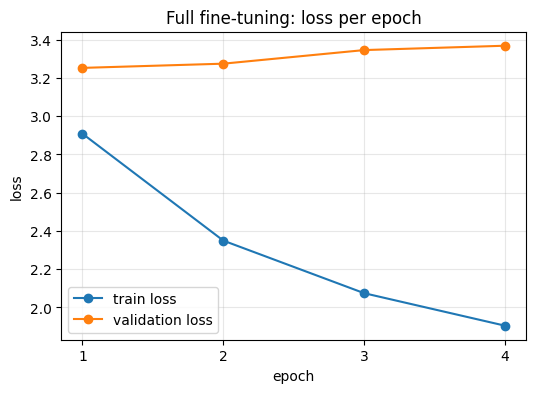

In [ ]:
%pip -q install peft ctranslate2
import matplotlib.pyplot as plt

# Per-epoch losses copied from the full fine-tuning log above (the Trainer object was freed to save GPU memory)
ep = [1, 2, 3, 4]
full_train = [2.908647, 2.349479, 2.074572, 1.904603]
full_val   = [3.252496, 3.274501, 3.345634, 3.368372]
plt.figure(figsize=(6, 4))
plt.plot(ep, full_train, marker="o", label="train loss")
plt.plot(ep, full_val, marker="o", label="validation loss")
plt.xticks(ep); plt.xlabel("epoch"); plt.ylabel("loss"); plt.grid(alpha=0.3); plt.legend()
plt.title("Full fine-tuning: loss per epoch"); plt.show()

In [ ]:
!pip install -U "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 15.8 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

W1109 14:06:01.468000 640 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


trainable params: 4,718,592 || all params: 488,624,128 || trainable%: 0.9657


Epoch,Training Loss,Validation Loss
1,3.274371,3.169984
2,3.025422,3.191413
3,2.832292,3.215272
4,2.683672,3.245334
5,2.672357,3.266068
6,2.664255,3.271433


LoRA training time (min): 15.1
adapter size (MB): 18.9


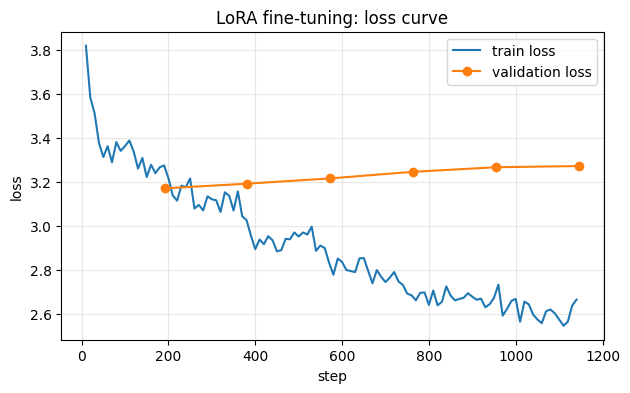

In [ ]:
from peft import LoraConfig, get_peft_model
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

full_model = model                                   # keep the full fine-tuned model for the comparison
DEC_START = full_model.config.decoder_start_token_id

# LoRA (Low-Rank Adaptation): small trainable low-rank matrices on the attention projections, all other weights frozen
base = M2M100ForConditionalGeneration.from_pretrained("facebook/m2m100_418M").to(device)
base.config.use_cache = False
lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                      target_modules=["q_proj", "k_proj", "v_proj", "out_proj"], task_type="SEQ_2_SEQ_LM")
lora_model = get_peft_model(base, lora_cfg)
lora_model.print_trainable_parameters()              # trainable share of the 418M parameters

tok.tgt_lang = "en"
def encode(df):
    # The source language token depends on each row, so tokenize row by row
    rows = []
    for l, s, t in zip(df.src_lang, df.source_text, df.target_en):
        tok.src_lang = MAP[l]
        rows.append(tok(s, text_target=t, max_length=SRC_MAX, truncation=True))
    return rows
train_ds, val_ds = encode(tr), encode(val)

base_collator = DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100)
def collate_lora(features):
    batch = base_collator(features)
    labels = batch["labels"]
    # Teacher forcing: decoder input = labels shifted right, starting with the decoder start token
    dec = labels.new_full(labels.shape, tok.pad_token_id)
    dec[:, 1:] = labels[:, :-1]
    dec[:, 0] = DEC_START
    dec[dec == -100] = tok.pad_token_id
    batch["decoder_input_ids"] = dec
    return batch

# LoRA needs a much higher learning rate than full fine-tuning because only the small adapters are updated
common = dict(output_dir=f"{WORK}/lora_tmp", per_device_train_batch_size=8, gradient_accumulation_steps=4,
              per_device_eval_batch_size=16, learning_rate=5e-4, warmup_steps=40, lr_scheduler_type="linear",
              num_train_epochs=6, weight_decay=0.0, label_smoothing_factor=0.1, fp16=True,
              save_strategy="no", logging_steps=10, report_to="none", seed=SEED,
              remove_unused_columns=False, label_names=["labels"])
try:
    args = Seq2SeqTrainingArguments(eval_strategy="epoch", **common)
except TypeError:
    args = Seq2SeqTrainingArguments(evaluation_strategy="epoch", **common)

trainer = Seq2SeqTrainer(model=lora_model, args=args, train_dataset=train_ds,
                         eval_dataset=val_ds, data_collator=collate_lora)
t0 = time.time(); trainer.train(); print("LoRA training time (min):", round((time.time() - t0) / 60, 1))

# Save only the adapter (a few MB) and report its size
lora_model.save_pretrained(f"{WORK}/lora_adapter")
adapter_mb = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(f"{WORK}/lora_adapter") for f in fs) / 1e6
print("adapter size (MB):", round(adapter_mb, 1))

# Loss curve from the Trainer log
log = pd.DataFrame(trainer.state.log_history)
tl, el = log[log["loss"].notna()], log[log["eval_loss"].notna()]
plt.figure(figsize=(7, 4))
plt.plot(tl["step"], tl["loss"], label="train loss"); plt.plot(el["step"], el["eval_loss"], marker="o", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=0.3); plt.legend(); plt.title("LoRA fine-tuning: loss curve"); plt.show()

# Merge the adapter into the base weights for fast inference
lora_model = trainer.model.merge_and_unload().half().eval()
lora_model.config.use_cache = True
del trainer; gc.collect(); torch.cuda.empty_cache()

In [ ]:
results["LoRA (r=16), beam5 + no_repeat_ngram 3"] = evaluate(lora_model, val, "LoRA, beam 5 + no_repeat_ngram_size 3", GEN_FINAL)
summary = pd.DataFrame({k: v[["BLEU", "chrF++"]].mean() for k, v in results.items()}).T.round(2)
print("\n=== Ablation (macro average) ===\n", summary)

# Pick the best fine-tuned model by macro chrF++ and keep it as `model` for the rest of the notebook
best_name = summary["chrF++"].idxmax()
model = lora_model if best_name.startswith("LoRA") else full_model
print("best model:", best_name)


LoRA, beam 5 + no_repeat_ngram_size 3
        n   BLEU  chrF++
lang                    
ben   129  24.56   51.69
guj    83  12.94   37.27
hin   150  31.35   57.02
mal    72  17.72   44.04
mar    94  24.11   49.17
tam   116  12.59   35.51
urd    53  19.79   45.22
Macro avg: {'BLEU': 20.44, 'chrF++': 45.7}

=== Ablation (macro average) ===
                                          BLEU  chrF++
zero-shot, beam4                        16.26   40.79
fine-tuned, beam4                       19.13   44.81
fine-tuned, beam5 + no_repeat_ngram 3   19.89   45.51
LoRA (r=16), beam5 + no_repeat_ngram 3  20.44   45.70
best model: LoRA (r=16), beam5 + no_repeat_ngram 3


## Final competition submission (selected validation-best model)

This cell intentionally runs **after model selection**. It overwrites the earlier provisional submission with predictions from the selected model (LoRA in this recorded run).

In [ ]:
# Regenerate the official submission using the selected model from Section 7.
# This must run AFTER the LoRA/full-fine-tuning comparison and model selection.
test = test.reset_index(drop=True)
t0 = time.time()
final_hyp, _ = translate_df(model, test, GEN_FINAL, bs=32)

final_submission = pd.DataFrame({
    "id": test["id"].values,
    "prediction": pd.Series(final_hyp).fillna("").astype(str).values
})
blank = final_submission["prediction"].str.strip().eq("")
print("blank predictions before fallback:", int(blank.sum()))
final_submission.loc[blank, "prediction"] = test.loc[blank, "source_text"].values

assert len(final_submission) == 3563, f"Expected 3563 rows, got {len(final_submission)}"
assert final_submission["id"].tolist() == test["id"].tolist(), "ID order mismatch"
assert final_submission["prediction"].notna().all()
assert final_submission["prediction"].str.strip().ne("").all()
assert list(final_submission.columns) == ["id", "prediction"]

final_submission_path = f"{WORK}/submission.csv"
final_submission.to_csv(final_submission_path, index=False)
print("Selected model:", best_name)
print("Saved:", final_submission_path)
print("Rows:", len(final_submission), "| elapsed minutes:", round((time.time() - t0) / 60, 2))
print(final_submission.head())

In [ ]:
!pip install -U nvidia-cublas-cu12 nvidia-cudnn-cu12

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 716.6/716.6 MB 14.2 MB/s  0:00:33
  Attempting uninstall: nvidia-cudnn-cu12
    Found existing installation: nvidia-cudnn-cu12 9.28.0.42
    Uninstalling nvidia-cudnn-cu12-9.28.0.42:
      Successfully uninstalled nvidia-cudnn-cu12-9.28.0.42


In [ ]:
# The model dir to convert: full fine-tuned weights, or the merged LoRA weights if LoRA won
if model is lora_model:
    BEST_DIR = f"{WORK}/lora_merged"; model.save_pretrained(BEST_DIR); tok.save_pretrained(BEST_DIR)
else:
    BEST_DIR = MODEL_DIR
CT2_DIR = f"{WORK}/ct2_int8"
!ct2-transformers-converter --model {BEST_DIR} --output_dir {CT2_DIR} --quantization int8_float16 --force

gpu_tr = ctranslate2.Translator(CT2_DIR, device="cuda")
cpu_tr = ctranslate2.Translator(CT2_DIR, device="cpu", compute_type="int8", intra_threads=os.cpu_count())

def ct2_translate(tr, df, bs=32):
    # Same preprocessing as the PyTorch path; the decoder is forced to start with the English token
    outs = pd.Series([None] * len(df), index=df.index, dtype=object)
    for l, g in df.groupby("src_lang"):
        tok.src_lang = MAP[l]
        src = [tok.convert_ids_to_tokens(tok(t, truncation=True, max_length=SRC_MAX).input_ids) for t in g.source_text]
        res = tr.translate_batch(src, target_prefix=[["__en__"]] * len(src), beam_size=5,
                                 no_repeat_ngram_size=3, max_decoding_length=TGT_MAX, max_batch_size=bs)
        outs.loc[g.index] = [tok.decode(tok.convert_tokens_to_ids(r.hypotheses[0][1:]), skip_special_tokens=True) for r in res]
    return outs

def timed(fn, n):
    torch.cuda.synchronize(); t0 = time.perf_counter(); out = fn(); torch.cuda.synchronize()
    return out, (time.perf_counter() - t0) * 1000 / n

def chrf(df, hyp):
    return sacrebleu.corpus_chrf(hyp.loc[df.index].tolist(), [df.target_en.tolist()], word_order=2).score

def dir_mb(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e6

bench = val.groupby("src_lang").head(30)     # 210 sentences across all 7 languages
small = val.groupby("src_lang").head(5)      # 35 sentences for single-sentence latency and the slow CPU test
one = lambda df, i: df.iloc[[i]]

# Warm-up so one-off CUDA initialisation does not distort the timings
translate_df(model, small.head(7), GEN_FINAL); ct2_translate(gpu_tr, small.head(7))

rows = []
h, ms_b = timed(lambda: translate_df(model, bench, GEN_FINAL)[0], len(bench))
_, ms_1 = timed(lambda: [translate_df(model, one(small, i), GEN_FINAL) for i in range(len(small))], len(small))
rows.append(["PyTorch fp16, GPU", round(ms_b, 1), round(ms_1, 1), round(chrf(bench, h), 2), round(dir_mb(BEST_DIR))])

h, ms_b = timed(lambda: ct2_translate(gpu_tr, bench), len(bench))
_, ms_1 = timed(lambda: [ct2_translate(gpu_tr, one(small, i)) for i in range(len(small))], len(small))
rows.append(["CTranslate2 int8_float16, GPU", round(ms_b, 1), round(ms_1, 1), round(chrf(bench, h), 2), round(dir_mb(CT2_DIR))])

# CPU int8: the edge scenario (no GPU); only single-sentence latency is measured
t0 = time.perf_counter(); parts = [ct2_translate(cpu_tr, one(small, i)) for i in range(len(small))]
ms_cpu = (time.perf_counter() - t0) * 1000 / len(small)
rows.append(["CTranslate2 int8, CPU", None, round(ms_cpu, 1), round(chrf(small, pd.concat(parts)), 2), round(dir_mb(CT2_DIR))])

bench_df = pd.DataFrame(rows, columns=["setup", "ms/sentence (batch 32)", "ms/sentence (batch 1)", "chrF++", "size MB"])
print(bench_df.to_string(index=False))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

W1109 14:39:11.233000 22030 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1109 14:39:11.289000 22030 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100% 509/509 [00:00<00:00, 5465.49it/s]
                        setup  ms/sentence (batch 32)  ms/sentence (batch 1)  chrF++  size MB
            PyTorch fp16, GPU                    74.0                  581.1   44.89      974
CTranslate2 int8_float16, GPU                    26.7                  200.9   45.19      491
        CTranslate2 int8, CPU                     NaN                 2595.4   45.69      491


## 11. Conclusions and limitations

**Findings (see the tables above for the numbers from this run)**
- Fine-tuning `m2m100_418M` on the provided pairs lifts the weakest languages the most, because zero-shot output for them was often degenerate or repetitive.
- Blocking repeated trigrams during beam search improves the output at no training cost.
- Model confidence (sequence log-probability) can be used to flag translations that need human review; the correlation printed in section 8 shows how reliable that signal is.

**Limitations**
- The data is multi-parallel (one English sentence appears in several languages). A random split leaks answers into validation and inflates scores, so this notebook uses a grouped split; scores from a random split are not comparable.
- Coverage is limited to the 7 training languages. Hindi and Marathi cannot be told apart by script alone.
- Validation sets are small per language (about 50 to 150 sentences), so differences of 1 to 2 points are within noise.
- Confidence flags are a heuristic and do not replace human evaluation.

**Future work:** balanced language sampling, parameter-efficient fine-tuning (LoRA, Low-Rank Adaptation), checkpoint averaging and a final retrain on all available pairs once the configuration is fixed.